In [1]:
# 1. Librerías (mismo estilo de la Lección 1)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

plt.style.use('ggplot')

In [2]:
# 2. Extracción de Iris.csv desde el enlace de la actividad
url = "https://gist.githubusercontent.com/netj/8836201/raw/6f9306ad21398ea43cba4f7d537619d0e07d5ae3/iris.csv"
df = pd.read_csv(url)

print("Dimensiones del DataFrame:", df.shape)
display(df.head())

Dimensiones del DataFrame: (150, 5)


,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [13]:
# Variables numéricas (individuos = flores, características = medidas)
X = df[['sepal.length', 'sepal.width', 'petal.length', 'petal.width']]
n_renglones = len(X)

In [14]:
# 3. Estandarización y PCA con pipeline
X_scaled = StandardScaler().fit_transform(X)

pca_pipe = make_pipeline(StandardScaler(), PCA())
pca_pipe.fit(X)
modelo_pca = pca_pipe.named_steps['pca']

In [6]:
# Eigenvalores ordenados y porcentaje de varianza explicada
eigenvalores = modelo_pca.explained_variance_
var_ratio = modelo_pca.explained_variance_ratio_
var_acum = np.cumsum(var_ratio)

resumen_var = pd.DataFrame({
    'Eigenvalor': eigenvalores,
    'Varianza_Explicada': var_ratio,
    'Varianza_Acumulada': var_acum
}, index=['PC1', 'PC2', 'PC3', 'PC4'])

print("Resumen de varianza por componente:")
display(resumen_var)
print(f"Varianza explicada con los 2 primeros componentes (PC1 + PC2): {var_acum[1]*100:.2f}%")

Resumen de varianza por componente:


,Eigenvalor,Varianza_Explicada,Varianza_Acumulada
PC1,2.938085,0.729624,0.729624
PC2,0.920165,0.228508,0.958132
PC3,0.147742,0.036689,0.994821
PC4,0.020854,0.005179,1.000000


Varianza explicada con los 2 primeros componentes (PC1 + PC2): 95.81%


In [15]:
# 4. Proyecciones (Mapa de observaciones) y Factores (Mapa de factores)
proyecciones = pd.DataFrame(
    modelo_pca.transform(X_scaled),
    columns=['PC1', 'PC2', 'PC3', 'PC4'],
    index=df.index
)
proyecciones['variety'] = df['variety']

factores_2 = pd.DataFrame(
    modelo_pca.components_[:2, :].T,
    columns=['PC1', 'PC2'],
    index=X.columns
)

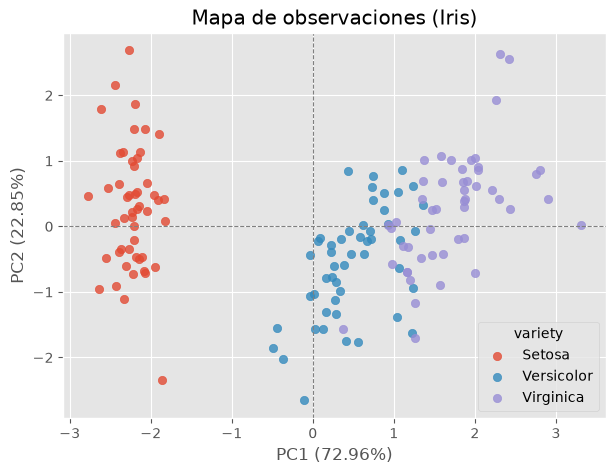

In [8]:
# Gráfico 1: Mapa de observaciones
fig, ax = plt.subplots(figsize=(7, 5))
for especie, grupo in proyecciones.groupby('variety'):
    ax.scatter(grupo['PC1'], grupo['PC2'], label=especie, alpha=0.8)

ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title("Mapa de observaciones (Iris)")
ax.set_xlabel(f"PC1 ({var_ratio[0]*100:.2f}%)")
ax.set_ylabel(f"PC2 ({var_ratio[1]*100:.2f}%)")
ax.legend(title="variety")
plt.show()


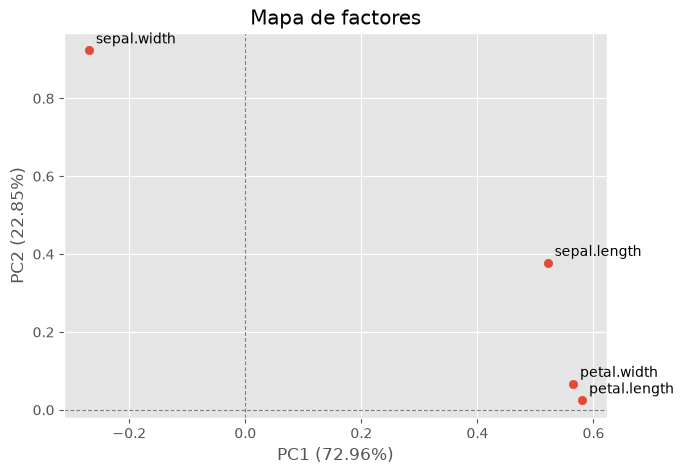

In [9]:
# Gráfico 2: Mapa de factores
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(factores_2['PC1'], factores_2['PC2'])
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title("Mapa de factores")
ax.set_xlabel(f"PC1 ({var_ratio[0]*100:.2f}%)")
ax.set_ylabel(f"PC2 ({var_ratio[1]*100:.2f}%)")

for i, txt in enumerate(factores_2.index):
    ax.annotate(txt, (factores_2['PC1'].iloc[i], factores_2['PC2'].iloc[i]),
                xytext=(5, 5), textcoords='offset points')
plt.show()

In [10]:
# 5. Corroboración con casos específicos en el DataFrame
df_analisis = pd.concat([df, proyecciones[['PC1', 'PC2']]], axis=1)

print("Promedios por especie en variables originales y componentes:")
display(df_analisis.groupby('variety')[['sepal.length', 'sepal.width', 'petal.length', 'petal.width', 'PC1', 'PC2']].mean())

Promedios por especie en variables originales y componentes:


,sepal.length,sepal.width,petal.length,petal.width,PC1,PC2
variety,,,,,,
Setosa,5.006,3.428,1.462,0.246,-2.224753,0.288927
Versicolor,5.936,2.770,4.260,1.326,0.496448,-0.550170
Virginica,6.588,2.974,5.552,2.026,1.728305,0.261243


In [11]:
# Ejemplos puntuales: menor PC1 (Setosa), intermedio (Versicolor) y mayor PC1 / PC2 (Virginica)
indices_ejemplo = [
    df_analisis[df_analisis['variety'] == 'Setosa']['PC1'].idxmin(),
    df_analisis[df_analisis['variety'] == 'Versicolor']['PC1'].idxmax(),
    df_analisis[df_analisis['variety'] == 'Virginica']['PC1'].idxmax(),
    df_analisis[df_analisis['variety'] == 'Virginica']['PC2'].idxmax()
]
print("Casos específicos corroborados en el DataFrame:")
display(df_analisis.loc[indices_ejemplo])

Casos específicos corroborados en el DataFrame:


,sepal.length,sepal.width,petal.length,petal.width,variety,PC1,PC2
22,4.6,3.6,1.0,0.2,Setosa,-2.774345,0.458344
77,6.7,3.0,5.0,1.7,Versicolor,1.358405,0.331312
118,7.7,2.6,6.9,2.3,Virginica,3.310696,0.017781
131,7.9,3.8,6.4,2.0,Virginica,2.304928,2.626323
